In [1]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Lambda,Dropout
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping
import shap
import warnings
import logging
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler     
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.utils import check_array
from tensorflow.keras.losses import mean_squared_error
import seaborn as sns
from sklearn.utils.validation import check_is_fitted
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l2
from mpl_toolkits.mplot3d import Axes3D
import tensorflow as tf
import math
from sklearn.metrics import roc_auc_score
from scipy.optimize import curve_fit
from itertools import combinations
from keras.models import load_model

from ODBAE import ODBAE

In [2]:
warnings.filterwarnings("ignore")
logger = logging.getLogger('shap')
logger.disabled = True

hidden_activation='relu'
output_activation='sigmoid'
loss=mean_squared_error
optimizer='adam'
epochs=60
batch_size=64
dropout_rate=0.2
l2_regularizer=10e-7
verbose=1
contamination=0.1

Loading dataset

In [3]:
X_test_raw=pd.read_csv('Data/IMPC_metabolism_experiment.csv')
X_train_raw=pd.read_csv('Data/IMPC_metabolism_control.csv')
X_test_raw_center=pd.DataFrame()
X_train_raw_center=pd.DataFrame()
for i in range(X_test_raw.shape[1]):
    X_test_raw_center[X_test_raw.columns[i]]=X_test_raw[X_test_raw.columns[i]]
for i in range(X_train_raw.shape[1]):
    X_train_raw_center[X_train_raw.columns[i]]=X_train_raw[X_train_raw.columns[i]]
    
X_test_raw_center['phenotyping_center_use']=X_test_raw['phenotyping_center']
X_train_raw_center['phenotyping_center_use']=X_train_raw['phenotyping_center']

center_list=X_test_raw_center.phenotyping_center.unique().tolist()
X_train_raw_center=X_train_raw_center.set_index('phenotyping_center')
X_test_raw_center=X_test_raw_center.set_index('phenotyping_center')

In [4]:
X_train_with_center=pd.DataFrame()
X_test_with_center=pd.DataFrame()
X_train_with_center_tmp=pd.DataFrame()
X_test_with_center_tmp=pd.DataFrame()
normalize=MinMaxScaler()
normalize2=StandardScaler()

for i in range(len(center_list)):
    center=center_list[i]
    X_train_center=X_train_raw_center.loc[center]
    X_test_center=X_test_raw_center.loc[center]
    X_train_center=X_train_center.reset_index(drop=True)
    X_test_center=X_test_center.reset_index(drop=True)

    X_train_tmp=pd.DataFrame()
    X_train_tmp=X_train_tmp.append(X_train_center.iloc[:,4:X_train_center.shape[1]-1])

    X_test_tmp=pd.DataFrame()
    X_test_tmp=X_test_tmp.append(X_test_center.iloc[:,7:X_test_center.shape[1]-1])
    
    # Normalization
    X_train_normalize_tmp=pd.DataFrame(normalize2.fit_transform(X_train_tmp),columns=X_train_tmp.columns)
    X_test_normalize_tmp=pd.DataFrame(normalize2.transform(X_test_tmp),columns=X_test_tmp.columns)
    
    X_train_normalize_tmp['phenotyping_center']=X_train_center['phenotyping_center_use']
    X_train_normalize_tmp['sex']=X_train_center['sex']
    X_test_normalize_tmp['phenotyping_center']=X_test_center['phenotyping_center_use']
    X_test_normalize_tmp['gene_symbol']=X_test_center['gene_symbol']
    X_test_normalize_tmp['sex']=X_test_center['sex']
    
    X_train_with_center_tmp=X_train_with_center_tmp.append(X_train_normalize_tmp)
    X_test_with_center_tmp=X_test_with_center_tmp.append(X_test_normalize_tmp)

X_train_with_center_tmp=X_train_with_center_tmp.reset_index(drop=True)
X_test_with_center_tmp=X_test_with_center_tmp.reset_index(drop=True)
X_train_with_center_tmp1=pd.DataFrame()
X_train_with_center_tmp1=X_train_with_center_tmp1.append(X_train_with_center_tmp.iloc[:,0:X_train_with_center_tmp.shape[1]-2])
X_test_with_center_tmp1=pd.DataFrame()
X_test_with_center_tmp1=X_test_with_center_tmp1.append(X_test_with_center_tmp.iloc[:,0:X_test_with_center_tmp.shape[1]-3])

X_train_with_center=pd.DataFrame(normalize.fit_transform(X_train_with_center_tmp1),columns=X_train_tmp.columns)
X_test_with_center=pd.DataFrame(normalize.transform(X_test_with_center_tmp1),columns=X_test_tmp.columns)
X_train_with_center['phenotyping_center']=X_train_with_center_tmp['phenotyping_center']
X_train_with_center['sex']=X_train_with_center_tmp['sex']
X_test_with_center['phenotyping_center']=X_test_with_center_tmp['phenotyping_center']
X_test_with_center['gene_symbol']=X_test_with_center_tmp['gene_symbol']
X_test_with_center['sex']=X_test_with_center_tmp['sex']

X_train_without_center=pd.DataFrame()
X_train_without_center=X_train_without_center.append(X_train_with_center.iloc[:,0:X_train_with_center.shape[1]-2])
X_test_without_center=pd.DataFrame()
X_test_without_center=X_test_without_center.append(X_test_with_center.iloc[:,0:X_test_with_center.shape[1]-3])

Dividing dataset

In [5]:
# male
sex_filter1='male'

X_train_sex=X_train_with_center.set_index('sex')
X_test_sex=X_test_with_center.set_index('sex')
X_train_sex_filter_male_tmp=X_train_sex.loc[sex_filter1]
X_test_sex_filter_male_tmp=X_test_sex.loc[sex_filter1]
X_train_sex_filter_male_tmp=X_train_sex_filter_male_tmp.reset_index(drop=True)
X_test_sex_filter_male_tmp=X_test_sex_filter_male_tmp.reset_index(drop=True)
X_train_sex_filter_male=pd.DataFrame()
X_train_sex_filter_male=X_train_sex_filter_male.append(X_train_sex_filter_male_tmp.iloc[:,0:X_train_sex_filter_male_tmp.shape[1]-1])
X_test_sex_filter_male=pd.DataFrame()
X_test_sex_filter_male=X_test_sex_filter_male.append(X_test_sex_filter_male_tmp.iloc[:,0:X_test_sex_filter_male_tmp.shape[1]-2])
X_test_sex_filter_male_gene=pd.DataFrame()
X_test_sex_filter_male_gene=X_test_sex_filter_male_gene.append(X_test_sex_filter_male_tmp.iloc[:,0:X_test_sex_filter_male_tmp.shape[1]])

X_train_sex_original=X_train_with_center_tmp.set_index('sex')
X_test_sex_original=X_test_with_center_tmp.set_index('sex')
X_train_sex_filter_male_tmp_original=X_train_sex_original.loc[sex_filter1]
X_test_sex_filter_male_tmp_original=X_test_sex_original.loc[sex_filter1]
X_train_sex_filter_male_tmp_original=X_train_sex_filter_male_tmp_original.reset_index(drop=True)
X_test_sex_filter_male_tmp_original=X_test_sex_filter_male_tmp_original.reset_index(drop=True)
X_train_sex_filter_male_original=pd.DataFrame()
X_train_sex_filter_male_original=X_train_sex_filter_male_original.append(X_train_sex_filter_male_tmp_original.iloc[:,0:X_train_sex_filter_male_tmp_original.shape[1]-1])
X_test_sex_filter_male_original=pd.DataFrame()
X_test_sex_filter_male_original=X_test_sex_filter_male_original.append(X_test_sex_filter_male_tmp_original.iloc[:,0:X_test_sex_filter_male_tmp_original.shape[1]-2])
X_test_sex_filter_male_gene_original=pd.DataFrame()
X_test_sex_filter_male_gene_original=X_test_sex_filter_male_gene_original.append(X_test_sex_filter_male_tmp_original.iloc[:,0:X_test_sex_filter_male_tmp_original.shape[1]])

# female
sex_filter2='female'

X_train_sex_filter_female_tmp=X_train_sex.loc[sex_filter2]
X_test_sex_filter_female_tmp=X_test_sex.loc[sex_filter2]
X_train_sex_filter_female_tmp=X_train_sex_filter_female_tmp.reset_index(drop=True)
X_test_sex_filter_female_tmp=X_test_sex_filter_female_tmp.reset_index(drop=True)
X_train_sex_filter_female=pd.DataFrame()
X_train_sex_filter_female=X_train_sex_filter_female.append(X_train_sex_filter_female_tmp.iloc[:,0:X_train_sex_filter_female_tmp.shape[1]-1])
X_test_sex_filter_female=pd.DataFrame()
X_test_sex_filter_female=X_test_sex_filter_female.append(X_test_sex_filter_female_tmp.iloc[:,0:X_test_sex_filter_female_tmp.shape[1]-2])
X_test_sex_filter_female_gene=pd.DataFrame()
X_test_sex_filter_female_gene=X_test_sex_filter_female_gene.append(X_test_sex_filter_female_tmp.iloc[:,0:X_test_sex_filter_female_tmp.shape[1]])

X_train_sex_filter_female_tmp_original=X_train_sex_original.loc[sex_filter2]
X_test_sex_filter_female_tmp_original=X_test_sex_original.loc[sex_filter2]
X_train_sex_filter_female_tmp_original=X_train_sex_filter_female_tmp_original.reset_index(drop=True)
X_test_sex_filter_female_tmp_original=X_test_sex_filter_female_tmp_original.reset_index(drop=True)
X_train_sex_filter_female_original=pd.DataFrame()
X_train_sex_filter_female_original=X_train_sex_filter_female_original.append(X_train_sex_filter_female_tmp_original.iloc[:,0:X_train_sex_filter_female_tmp_original.shape[1]-1])
X_test_sex_filter_female_original=pd.DataFrame()
X_test_sex_filter_female_original=X_test_sex_filter_female_original.append(X_test_sex_filter_female_tmp_original.iloc[:,0:X_test_sex_filter_female_tmp_original.shape[1]-2])
X_test_sex_filter_female_gene_original=pd.DataFrame()
X_test_sex_filter_female_gene_original=X_test_sex_filter_female_gene_original.append(X_test_sex_filter_female_tmp_original.iloc[:,0:X_test_sex_filter_female_tmp_original.shape[1]])

In [6]:
X_test_raw = X_test_sex_filter_male_gene.iloc[:,0:14]
X_test_raw['gene_symbol'] = X_test_sex_filter_male_gene['gene_symbol']

X_train_raw = X_train_sex_filter_male
train_category = []
for i in range(X_train_raw.shape[0]):
    train_category.append('None')
X_train_raw['gene_symbol'] = train_category
X_train_raw = X_train_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

Revised loss function

In [7]:
def def_loss(y_actual,y_pred):
    data_real_dim=11      # intrinsic dimension
    
    y_actual_tensor=tf.subtract(y_actual,0,name=None)
    y_actual_tensor=tf.cast(y_actual_tensor, tf.float64)
    y_pred_tensor=tf.subtract(y_pred,0,name=None)
    y_pred_tensor=tf.cast(y_pred_tensor, tf.float64)
    mean_actual_tensor = tf.reduce_mean(y_actual_tensor, axis=0, keepdims=True)
    mean_pred_tensor = tf.reduce_mean(y_pred_tensor, axis=0, keepdims=True)
    cov_actual= tf.matmul(tf.transpose(y_actual_tensor-mean_actual_tensor), y_actual_tensor-mean_actual_tensor)/tf.cast(tf.shape(y_actual_tensor)[0]-1, tf.float64)
    cov_pred= tf.matmul(tf.transpose(y_pred_tensor-mean_pred_tensor), y_pred_tensor-mean_pred_tensor)/tf.cast(tf.shape(y_pred_tensor)[0]-1, tf.float64)
    cov_inv_actual=tf.linalg.inv(cov_actual)
    mashi_loss=tf.reduce_sum(tf.matmul(y_actual_tensor-y_pred_tensor, cov_inv_actual)*(y_actual_tensor-y_pred_tensor))
    eigenvalues_actual, eigenvectors_actual=tf.linalg.eigh(cov_actual)
    eigenvalues_pred, eigenvectors_pred=tf.linalg.eigh(cov_pred)
    eigenvalues_actual_sort_to_control=tf.sort(eigenvalues_actual,direction='DESCENDING')[0:data_real_dim]
    eigenvalues_pred_sort_to_control=tf.sort(eigenvalues_pred,direction='DESCENDING')[0:data_real_dim]
    sqrt_eigenvalues_actual_to_control=tf.sqrt(eigenvalues_actual_sort_to_control, name=None)
    sqrt_eigenvalues_pred_to_control=tf.sqrt(eigenvalues_pred_sort_to_control, name=None)
    
    eigenvalues_actual_sort=tf.sort(eigenvalues_actual,direction='DESCENDING')
    sqrt_eigenvalues_actual=tf.sqrt(eigenvalues_actual_sort, name=None)
    beta_control_list=0.3*sqrt_eigenvalues_actual
    beta_list=sqrt_eigenvalues_actual
    max_beta_control_list=tf.reduce_max(beta_control_list)
    max_beta_control_list_reshape=tf.reshape(max_beta_control_list,[1])
    min_beta_list=tf.reduce_min(beta_list)
    min_beta_list_reshape=tf.reshape(min_beta_list,[1])
    combine_beta_list=tf.concat([max_beta_control_list_reshape,min_beta_list_reshape], axis=0)
    beta_control_value=tf.reduce_min(combine_beta_list)

    eigenvalues_diff=tf.subtract(sqrt_eigenvalues_actual_to_control,sqrt_eigenvalues_pred_to_control,name=None)
    eigenvalues_diff_cast=tf.cast(eigenvalues_diff,tf.float64)
    eigenvalues_diff_control=tf.subtract(eigenvalues_diff_cast,beta_control_value,name=None)
    eigenvalues_diff_control_square=tf.reduce_mean(tf.square(eigenvalues_diff_control))
    
    mean_loss=tf.reduce_mean(tf.square(y_actual_tensor-y_pred_tensor))
    final_loss=0.008*mean_loss+eigenvalues_diff_control_square
    
    return final_loss

Loading trained model

In [8]:
autoencoder = load_model('Trained_models/metabolic_analysis_male_trained_model',custom_objects={"def_loss":def_loss})

Outlier detection and analysis

In [9]:
outlier_detection_model = ODBAE(reconstruction_error_percent=0.5)  
category_based_anomaly_explanation, instance_based_anomaly_explanation = outlier_detection_model.outlier_analysis(x_train_raw=X_train_raw,  
                                                                 x_test_raw = X_test_raw, 
                                                                autoencoder = autoencoder,   
                                                                abnormal_rate = 0.1,
                                                                batch_parameter = None,
                                                                normalize = False,
                                                                category_parameter = 'gene_symbol')

1 128
2 128
3 128
4 128
5 128
6 128
7 128
8 128
9 128
10 128
11 128
12 128
13 128
14 128
15 128
16 128
17 128
18 128
19 128
20 128
21 128
22 128
23 128
24 128
25 128
26 128
27 128
28 128
29 128
30 128
31 128
32 128
33 128
34 128
35 128
36 128
37 128
38 128
39 128
40 128
41 128
42 128
43 128
44 128
45 128
46 128
47 128
48 128
49 128
50 128
51 128
52 128
53 128
54 128
55 128
56 128
57 128
58 128
59 128
60 128
61 128
62 128
63 128
64 128
65 128
66 128
67 128
68 128
69 128
70 128
71 128
72 128
73 128
74 128
75 128
76 128
77 128
78 128
79 128
80 128
81 128
82 128
83 128
84 128
85 128
86 128
87 128
88 128
89 128
90 128
91 128
92 128
93 128
94 128
95 128
96 128
97 128
98 128
99 128
100 128
101 128
102 128
103 128
104 128
105 128
106 128
107 128
108 128
109 128
110 128
111 128
112 128
113 128
114 128
115 128
116 128
117 128
118 128
119 128
120 128
121 128
122 128
123 128
124 128
125 128
126 128
127 128
128 128
1 1797
2 1797
3 1797
4 1797
5 1797
6 1797
7 1797
8 1797
9 1797
10 1797
11 1797
12 17

822 1797
823 1797
824 1797
825 1797
826 1797
827 1797
828 1797
829 1797
830 1797
831 1797
832 1797
833 1797
834 1797
835 1797
836 1797
837 1797
838 1797
839 1797
840 1797
841 1797
842 1797
843 1797
844 1797
845 1797
846 1797
847 1797
848 1797
849 1797
850 1797
851 1797
852 1797
853 1797
854 1797
855 1797
856 1797
857 1797
858 1797
859 1797
860 1797
861 1797
862 1797
863 1797
864 1797
865 1797
866 1797
867 1797
868 1797
869 1797
870 1797
871 1797
872 1797
873 1797
874 1797
875 1797
876 1797
877 1797
878 1797
879 1797
880 1797
881 1797
882 1797
883 1797
884 1797
885 1797
886 1797
887 1797
888 1797
889 1797
890 1797
891 1797
892 1797
893 1797
894 1797
895 1797
896 1797
897 1797
898 1797
899 1797
900 1797
901 1797
902 1797
903 1797
904 1797
905 1797
906 1797
907 1797
908 1797
909 1797
910 1797
911 1797
912 1797
913 1797
914 1797
915 1797
916 1797
917 1797
918 1797
919 1797
920 1797
921 1797
922 1797
923 1797
924 1797
925 1797
926 1797
927 1797
928 1797
929 1797
930 1797
931 1797
932 1797
9

1660 1797
1661 1797
1662 1797
1663 1797
1664 1797
1665 1797
1666 1797
1667 1797
1668 1797
1669 1797
1670 1797
1671 1797
1672 1797
1673 1797
1674 1797
1675 1797
1676 1797
1677 1797
1678 1797
1679 1797
1680 1797
1681 1797
1682 1797
1683 1797
1684 1797
1685 1797
1686 1797
1687 1797
1688 1797
1689 1797
1690 1797
1691 1797
1692 1797
1693 1797
1694 1797
1695 1797
1696 1797
1697 1797
1698 1797
1699 1797
1700 1797
1701 1797
1702 1797
1703 1797
1704 1797
1705 1797
1706 1797
1707 1797
1708 1797
1709 1797
1710 1797
1711 1797
1712 1797
1713 1797
1714 1797
1715 1797
1716 1797
1717 1797
1718 1797
1719 1797
1720 1797
1721 1797
1722 1797
1723 1797
1724 1797
1725 1797
1726 1797
1727 1797
1728 1797
1729 1797
1730 1797
1731 1797
1732 1797
1733 1797
1734 1797
1735 1797
1736 1797
1737 1797
1738 1797
1739 1797
1740 1797
1741 1797
1742 1797
1743 1797
1744 1797
1745 1797
1746 1797
1747 1797
1748 1797
1749 1797
1750 1797
1751 1797
1752 1797
1753 1797
1754 1797
1755 1797
1756 1797
1757 1797
1758 1797
1759 1797


In [10]:
category_based_anomaly_explanation_index = category_based_anomaly_explanation.set_index('category_col')
category_based_anomaly_explanation_index['explain_result']['Lepr']

category_col
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Lepr    [Alanine aminotransferase, HDL-cholesterol]
Name: explain_result, dtype: object

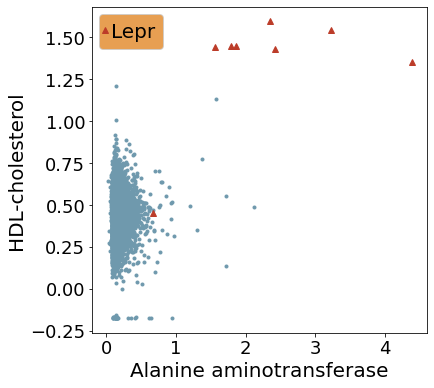

In [12]:
gene='Lepr'  
feature1 = 'Alanine aminotransferase'
feature2 = 'HDL-cholesterol'

category_based_anomaly_explanation_tmp = pd.DataFrame()
for i in range(category_based_anomaly_explanation.shape[1]):
    category_based_anomaly_explanation_tmp[category_based_anomaly_explanation.columns[i]]=category_based_anomaly_explanation[category_based_anomaly_explanation.columns[i]]
category_based_anomaly_explanation_tmp['index']=category_based_anomaly_explanation_tmp['original_index']
category_based_anomaly_explanation_tmp=category_based_anomaly_explanation_tmp.set_index('category_col')
ob_data_index=category_based_anomaly_explanation_tmp.loc[gene]
ob_data_index_list=ob_data_index.original_index.tolist()
ob_gene_data=pd.DataFrame()
gene_drop=pd.DataFrame()
for i in range(X_test_raw.shape[0]):
    if i in ob_data_index_list:
        ob_gene_data=ob_gene_data.append(X_test_raw[i:i+1])
    else:
        gene_drop=gene_drop.append(X_test_raw[i:i+1])

fig=plt.figure(figsize=(6,6)) 
plt.plot(gene_drop[feature1],gene_drop[feature2],'.',color='#6F99ADFF')
plt.plot(ob_gene_data[feature1],ob_gene_data[feature2],'^',color='#BC3C29FF',label=gene)

plt.tick_params(labelsize=18)
plt.xlabel(feature1,fontsize=20)
plt.ylabel(feature2,fontsize=20)
plt.legend(prop=dict(size=20),bbox_to_anchor=(0.02, 0.87),
           labelspacing=0,facecolor = '#E18727FF',loc=3,handlelength=-0.2,handletextpad=0.4,borderaxespad=0)

In [15]:
# category_based_anomaly_explanation.to_csv('Results/metabolic_female_category_based_anomaly_explanation.csv',index=False)
# instance_based_anomaly_explanation.to_csv('Results/metabolic_female_instance_based_anomaly_explanation.csv',index=False)